# ONA de bolso: a análise passo a passo

Se você trabalha com RH, provavelmente já viu este filme: sai uma pessoa e, de repente, ninguém mais sabe resolver um assunto. Ou um projeto trava entre duas áreas e o organograma não explica por quê.

O organograma diz quem responde a quem. Ele não diz por onde a informação passa. É isso que a análise de rede organizacional (ONA) mede.

Neste notebook, vamos fazer a análise inteira numa organização **fictícia** de 114 pessoas: da pergunta de negócio aos limites do que dá para concluir. Nenhum dado aqui é real; a base foi gerada por `scripts/gerar_base.py` com estrutura plantada de propósito, para a gente conferir se o método acha o que deveria.

## 1. A pergunta de negócio

Três perguntas aparecem em toda conversa de reorganização, sucessão ou integração:

1. **Que área virou silo?**
2. **Se essa pessoa sair, o que para de funcionar?**
3. **O gestor está no fluxo do próprio time?**

Para responder, basta um questionário de nomeação com duas perguntas, do tipo "com quem você trocou informação importante nas últimas 4 semanas?" e "a quem você pede ajuda quando trava?".

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

import ona_de_bolso as ona
from ona_de_bolso.relatorio import CORES

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10, "axes.titleweight": "bold", "axes.titlesize": 11})
pd.set_option("display.precision", 3)

## 2. Os dados

São duas tabelas. A de **pessoas** vem do cadastro do RH, com um código no lugar do nome. A de **ligações** vem do formulário: uma linha para cada colega citado (`origem_id` citou `destino_id`).

In [2]:
pessoas, ligacoes = ona.exemplo()
print(f"{len(pessoas)} pessoas, {len(ligacoes)} citações")
pessoas.head()

114 pessoas, 907 citações


,id,area,cargo,gestor_id,unidade,respondeu
0,P001,Comercial,Gestor,,São Paulo,sim
1,P002,Comercial,Especialista,P001,São Paulo,sim
2,P003,Comercial,Especialista,P001,São Paulo,sim
3,P004,Comercial,Especialista,P001,São Paulo,sim
4,P005,Comercial,Analista,P001,São Paulo,nao


In [3]:
ligacoes.head()

,origem_id,destino_id,tipo,peso
0,P001,P046,ajuda,1
1,P002,P003,informacao,4
2,P002,P005,ajuda,5
3,P002,P008,ajuda,4
4,P002,P008,informacao,1


In [4]:
resumo = pessoas.groupby("area").agg(pessoas=("id", "size"), responderam=("respondeu", lambda s: (s == "sim").sum()))
resumo["taxa"] = (resumo["responderam"] / resumo["pessoas"]).round(2)
resumo.sort_values("pessoas", ascending=False)

,pessoas,responderam,taxa
area,,,
Operações,34,30,0.88
Comercial,30,22,0.73
Tecnologia,22,19,0.86
Financeiro,16,12,0.75
Gente e Gestão,12,8,0.67


Antes de qualquer conta, confira a validação. Ela pega id repetido, citação de quem não está na tabela e coluna faltando.

In [5]:
erros, avisos = ona.validar(pessoas, ligacoes)
erros, avisos

([], [])

## 3. A rede

Aqui está a primeira escolha de método que muda o resultado. Quem não respondeu não cita ninguém. Se a rede usar só o sentido da citação, essa pessoa nunca aparece como ponte, mesmo que meia empresa a procure.

Por isso a análise usa a rede **simetrizada** para medir fluxo: se A citou B, existe ligação entre os dois. O sentido continua valendo para citações recebidas, reciprocidade e papéis de corretagem.

In [6]:
%%time
r = ona.analisar(pessoas, ligacoes)
print(f"{r['pessoas']} pessoas, {r['ligacoes']} pares ligados, taxa de resposta de {r['taxa_resposta']:.0%}")

114 pessoas, 720 pares ligados, taxa de resposta de 80%
CPU times: user 1.59 s, sys: 0 ns, total: 1.59 s
Wall time: 1.6 s


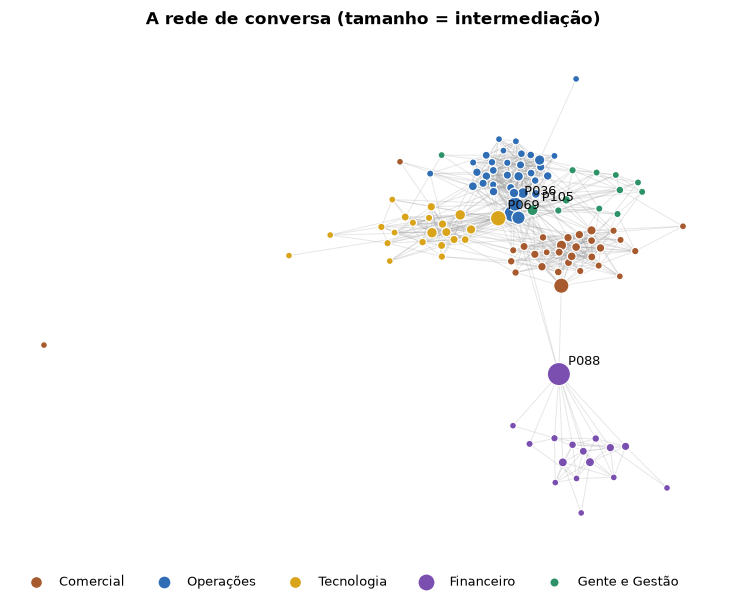

In [7]:
pos = ona.posicoes(r)
g = r.rede
areas = [a["area"] for a in r["areas"]]
cor = {a: CORES[i] for i, a in enumerate(areas)}
G = nx.relabel_nodes(g.G, {i: g.nos[i]["id"] for i in range(g.n)})
tab = r.pessoas_df().set_index("id")

fig, ax = plt.subplots(figsize=(8.5, 6.2))
nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#9a9a9a", alpha=0.25, width=0.6)
for a in areas:
    nos = tab.index[tab["area"] == a]
    nx.draw_networkx_nodes(G, pos, nodelist=list(nos), ax=ax, node_color=cor[a], label=a,
                           node_size=20 + 900 * tab.loc[nos, "intermediacao"], edgecolors="white", linewidths=0.8)
for pid in ["P088", "P036", "P069", "P105"]:
    x, y = pos[pid]
    ax.annotate(pid, (x, y), xytext=(6, 6), textcoords="offset points", fontsize=8.5, color="#0a0a0a")
ax.set_title("A rede de conversa (tamanho = intermediação)")
ax.legend(frameon=False, loc="lower left", fontsize=8.5, ncols=5, bbox_to_anchor=(0, -0.08))
ax.axis("off")
plt.show()

O Financeiro aparece pendurado no resto da empresa por um fio só. Vamos medir isso em vez de confiar no desenho.

## 4. As métricas

### Silo: o E-I com linha de base

O índice E-I (Krackhardt e Stern, 1988) compara ligações externas e internas de cada área, de -1 (só para dentro) a +1 (só para fora). O problema é que **toda** área conversa mais com o próprio time. Usar um corte fixo chama tudo de silo.

A saída é comparar com o acaso: embaralhamos as áreas entre as pessoas 1.000 vezes, mantendo a rede e o tamanho de cada área, e vemos qual E-I cada área teria. Silo é a área com E-I abaixo do esperado (p < 0,01) e com menos de 25% das ligações externas que teria ao acaso.

In [8]:
areas_df = r.areas_df()[["area", "pessoas", "ei", "ei_esperado", "p_valor", "externo_vs_acaso", "silo"]]
areas_df

,area,pessoas,ei,ei_esperado,p_valor,externo_vs_acaso,silo
0,Comercial,30,-0.430,0.707,9.990e-04,0.334,False
1,Operações,34,-0.537,0.661,9.990e-04,0.279,False
2,Tecnologia,22,-0.190,0.796,9.990e-04,0.451,False
3,Financeiro,16,-0.887,0.860,9.990e-04,0.061,True
4,Gente e Gestão,12,0.291,0.899,9.990e-04,0.680,False


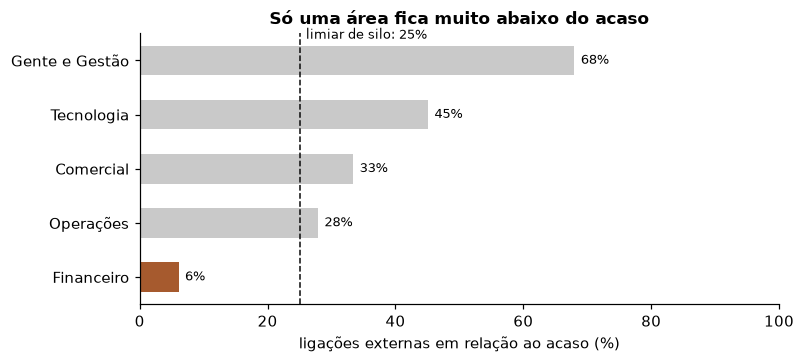

In [9]:
d = areas_df.sort_values("externo_vs_acaso")
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.barh(d["area"], d["externo_vs_acaso"] * 100, color=[CORES[0] if s else "#c9c9c9" for s in d["silo"]], height=0.55)
ax.axvline(25, color="#0a0a0a", lw=1, ls="--")
ax.text(26, len(d) - 0.6, "limiar de silo: 25%", fontsize=8.5)
for y, v in enumerate(d["externo_vs_acaso"] * 100):
    ax.text(v + 1, y, f"{v:.0f}%", va="center", fontsize=8.5)
ax.set_xlabel("ligações externas em relação ao acaso (%)")
ax.set_title("Só uma área fica muito abaixo do acaso")
ax.set_xlim(0, 100)
plt.show()

As cinco áreas estão abaixo do acaso, o que é normal. Só o Financeiro está **muito** abaixo: tem 6% das ligações externas que teria se as conversas ignorassem a área. As outras ficam entre 28% e 68%.

### Pontes: intermediação, dirigida x simetrizada

Intermediação (Brandes, 2001, pelo networkx) mede em quantos caminhos mais curtos entre dois colegas a pessoa está no meio.

In [10]:
cols = ["id", "area", "respondeu", "intermediacao_simetrizada", "intermediacao_dirigida", "restricao", "papel"]
tab.reset_index()[cols].sort_values("intermediacao_simetrizada", ascending=False).head(8)

,id,area,respondeu,intermediacao_simetrizada,intermediacao_dirigida,restricao,papel
87,P088,Financeiro,True,0.233,0.084,0.187,porteiro
33,P034,Operações,True,0.115,0.033,0.092,representante
68,P069,Tecnologia,True,0.093,0.142,0.066,representante
2,P003,Comercial,True,0.089,0.049,0.144,coordenador
35,P036,Operações,True,0.074,0.107,0.065,porteiro
38,P039,Operações,True,0.062,0.035,0.116,coordenador
104,P105,Gente e Gestão,False,0.035,0.000,0.096,NaN
40,P041,Operações,True,0.034,0.023,0.093,porteiro


Repare na P105: não respondeu ao questionário, tem intermediação **zero** na rede dirigida e fica entre as dez maiores na simetrizada. É a pessoa que quatro áreas procuram. Na rede só com o sentido citado, ela sumiria.

### Por onde a informação entra no time: Gould e Fernandez

Os papéis de corretagem (Gould e Fernandez, 1989) olham caminhos A → B → C em que A e C não se falam direto. O **porteiro** traz informação de fora para o próprio time.

In [11]:
r.areas_df()[["area", "entradas_de_fora", "porteiro_principal", "porteiro_participacao"]]

,area,entradas_de_fora,porteiro_principal,porteiro_participacao
0,Comercial,176,P025,0.142
1,Operações,438,P036,0.320
2,Tecnologia,295,P069,0.403
3,Financeiro,27,P088,1.000
4,Gente e Gestão,33,P103,0.455


No Financeiro, P088 responde por 100% das entradas de informação de fora.

### Grupos reais x organograma

O Louvain (Blondel et al., 2008) acha grupos de conversa. Como o resultado varia com a ordem de visita, a análise roda 20 vezes com sementes diferentes, fica a de maior modularidade e mede a concordância entre as execuções (Rand ajustado).

In [12]:
print(f"{r['comunidades']} grupos, modularidade {r['modularidade']:.3f}, concordância entre execuções {r['estabilidade_comunidades']:.2f}")
pd.crosstab(tab["area"], tab["comunidade"] + 1).rename_axis(index="área", columns="grupo")

5 grupos, modularidade 0.540, concordância entre execuções 0.90


grupo,1,2,3,4,5,6
área,,,,,,
Comercial,0,28,1,0,0,1
Financeiro,0,0,0,16,0,0
Gente e Gestão,0,0,1,0,11,0
Operações,33,0,1,0,0,0
Tecnologia,0,0,22,0,0,0


## 5. E se essa pessoa sair?

Esta é a pergunta que pesa para o gestor. A análise tira, uma de cada vez, as dez pessoas com maior intermediação e mede quem perde o caminho até o resto da rede e quanto cai a eficiência global (Latora e Marchiori, 2001).

In [13]:
riscos = r.riscos_df()[["id", "area", "perdem_caminho", "queda_eficiencia"]]
riscos

,id,area,perdem_caminho,queda_eficiencia
0,P088,Financeiro,15,0.138
1,P082,Tecnologia,1,0.015
2,P069,Tecnologia,0,0.015
3,P036,Operações,0,0.015
4,P034,Operações,0,0.013
5,P003,Comercial,0,0.008
6,P041,Operações,0,0.008
7,P039,Operações,0,0.008
8,P105,Gente e Gestão,0,0.007
9,P079,Tecnologia,0,0.005


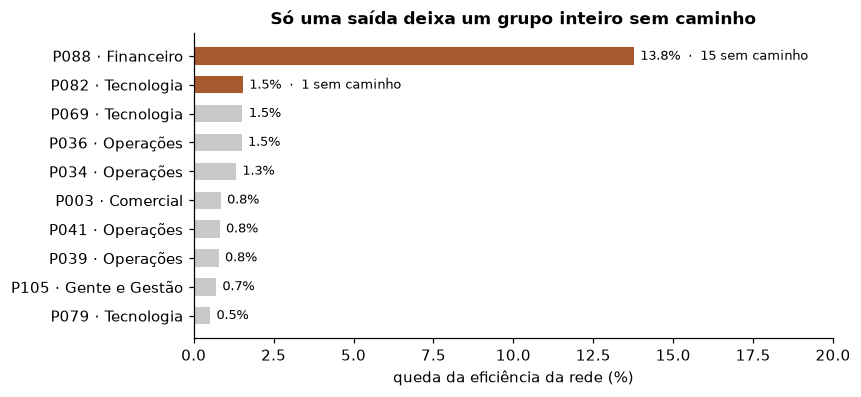

In [14]:
d = riscos.sort_values("queda_eficiencia")
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.barh(d["id"] + " · " + d["area"], d["queda_eficiencia"] * 100,
        color=[CORES[0] if p > 0 else "#c9c9c9" for p in d["perdem_caminho"]], height=0.6)
for y, (v, p) in enumerate(zip(d["queda_eficiencia"] * 100, d["perdem_caminho"], strict=True)):
    ax.text(v + 0.2, y, f"{v:.1f}%" + (f"  ·  {p} sem caminho" if p else ""), va="center", fontsize=8.5)
ax.set_xlabel("queda da eficiência da rede (%)")
ax.set_title("Só uma saída deixa um grupo inteiro sem caminho")
ax.set_xlim(0, 20)
plt.show()

In [15]:
sim = ona.simular_saida(r, ["P088"])
print(f"Sem P088: {len(sim['perdem_caminho'])} pessoas sem caminho ({sim['areas_afetadas']}), "
      f"eficiência de {sim['eficiencia_antes']:.3f} para {sim['eficiencia']:.3f} (-{sim['queda_eficiencia']:.0%})")
sim2 = ona.simular_saida(r, ["P036"])
print(f"Sem P036: ninguém perde o caminho, mas a distância média vai de {sim2['distancia_media_antes']:.2f} para {sim2['distancia_media']:.2f} passos")

Sem P088: 15 pessoas sem caminho ({'Financeiro': 15}), eficiência de 0.456 para 0.393 (-14%)
Sem P036: ninguém perde o caminho, mas a distância média vai de 2.56 para 2.60 passos


## 6. Os insights

A análise escreve os achados em português de gestor, do mais importante para o menos. Todos seguem a mesma regra: é diagnóstico da rede, não avaliação de pessoa.

In [16]:
for i in r["insights"]:
    print(f"[{i['nivel']}] {i['titulo']}\n    {i['texto']}\n")

[atencao] Taxa de resposta de 80%: leia com cautela
    23 pessoas não responderam. Elas aparecem quando alguém as cita, e a análise conta a ligação nos dois sentidos para não apagá-las. Simulando mais 10% de não resposta (20 sorteios), em média 87% das cinco maiores pontes continuam no topo e o diagnóstico de silo se repete em 100% dos sorteios. Ponto de atenção: a taxa de resposta está entre 70% e 85%.

[risco] Uma saída deixaria 15 pessoas sem caminho até o resto da rede
    Sem P088 (Financeiro), 15 pessoas, quase todas de Financeiro, deixam de ter qualquer caminho de conversa com o restante da organização, e a eficiência da rede cai 14%. É um ponto único de falha: o problema é a rede depender de uma pessoa só. Vale criar um segundo canal (rituais entre áreas, par de backup) antes que ele faça falta.

[risco] Financeiro fala quase só para dentro
    3 de 53 ligações da área cruzam a fronteira (E-I de -0,89). Se as conversas ignorassem a área, o esperado seria um E-I de 0,86: a área

## 7. Até onde dá para confiar

Questionário de nomeação tem não resposta, e ela fura a rede justamente nas ligações que faltam (Kossinets, 2006). Duas checagens:

- **regra de leitura**: abaixo de 70% de resposta, a análise não conclui sobre pontes, isolados, buracos estruturais nem dependência; de 70% a 85%, pede cautela;
- **sensibilidade**: apaga as citações de mais 10% de quem respondeu, 20 vezes, e confere se pontes e silo se mantêm (na linha de Borgatti, Carley e Krackhardt, 2006).

In [17]:
s = r["sensibilidade"]
print(f"Leitura: {r['confiabilidade']['nivel']} ({'; '.join(r['confiabilidade']['motivos'])})")
print(f"Pontes que continuam no top 5: {s['pontes_mantidas']:.0%} em média, {s['pontes_mantidas_min']:.0%} no pior sorteio")
print(f"Silo igual em {s['silo_estavel']:.0%} dos sorteios; isolados de {s['isolados_min']} a {s['isolados_max']}")

Leitura: cautela (a taxa de resposta está entre 70% e 85%)
Pontes que continuam no top 5: 87% em média, 40% no pior sorteio
Silo igual em 100% dos sorteios; isolados de 3 a 4


E o que acontece se a resposta cair para menos de 70%? Vamos simular: marcamos mais 20 pessoas como não respondentes e apagamos as citações delas.

In [18]:
resp = pessoas.loc[pessoas["respondeu"] == "sim", "id"].sample(20, random_state=5)
p2 = pessoas.assign(respondeu=lambda d: d["respondeu"].where(~d["id"].isin(resp), "nao"))
l2 = ligacoes[~ligacoes["origem_id"].isin(resp)]
r2 = ona.analisar(p2, l2, com_sensibilidade=False)
print(f"Taxa de resposta: {r2['taxa_resposta']:.0%} -> leitura {r2['confiabilidade']['nivel']}")
print(r2["insights"][0]["titulo"])
print("Insights de pontes ou dependência:", [i["titulo"] for i in r2["insights"] if i["tema"] in ("pontes", "dependencia")])

Taxa de resposta: 62% -> leitura insuficiente
Só 62% responderam: não dá para concluir sobre pontes e isolados
Insights de pontes ou dependência: []


## 8. Limites e cuidados

- O questionário mede a percepção de quem respondeu, num momento. Não é registro de interação.
- Os papéis de corretagem dependem do sentido da citação; quem não respondeu não aparece como porteiro.
- O limiar de silo (25%) é uma escolha de leitura, documentada, não um valor universal.
- Resultados por área só aparecem com 5 pessoas ou mais, e a tabela por pessoa fica fora do relatório.
- Intermediação alta não é desempenho alto. Isolamento é sinal para conversar. Nenhuma métrica daqui deve entrar em avaliação, promoção ou desligamento.

Para levar ao gestor, gere o relatório HTML:

```bash
ona-de-bolso analisar pessoas.csv ligacoes.csv --saida relatorio.html
```